In [1]:
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.lib.distances import distance_array

TOP    = "md_amber_0_1.gro"   # topology/structure of the WHOLE system (33594 atoms)
TRAJ   = "500ns.xtc"          # trajectory file
CUTOFF = 4.5                  # Å (MDAnalysis uses Angstroms) = 0.45 nm
T_START, T_END = 250.0, 500.0 # ns, analysis time window
STEP   = 10                   # stride (take every 10th frame)

u = mda.Universe(TOP, TRAJ)
print("Atoms:", u.atoms.n_atoms, " | Frames:", len(u.trajectory))
print(f"Time range (ns): {u.trajectory[0].time / 1000:.1f} - {u.trajectory[-1].time / 1000:.1f}")

/home/magnetic/miniconda3/envs/amber/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Atoms: 33594  | Frames: 250001
Time range (ns): 0.0 - 500.0


In [3]:
pep1 = u.atoms[:256]
pep2 = u.atoms[256:512]
print(pep1.residues.resnames[[0, -1]], pep2.residues.resnames[[0, -1]])  # expected: ASP ... LYS

heavy1 = pep1.select_atoms("not name H*")
heavy2 = pep2.select_atoms("not name H*")

def residue_starts(heavy):
    idx = heavy.resindices - heavy.resindices[0]       # 0..15 for each atom
    return np.r_[0, np.where(np.diff(idx) != 0)[0] + 1]  # start index of each residue

starts1, starts2 = residue_starts(heavy1), residue_starts(heavy2)
print(len(starts1), len(starts2))   # should be 16 and 16

seq = "DAEFRHDSGYEVHHQK"
labels = [f"{a}{i+1}" for i, a in enumerate(seq)]

['ASP' 'LYS'] ['ASP' 'LYS']
16 16


In [5]:
n = 16
count = np.zeros((n, n))   # residue pairs (Pep1 i, Pep2 j) in contact
any1 = np.zeros(n)         # Pep1 residue contacts at least one residue in Pep2
any2 = np.zeros(n)         # Pep2 residue contacts at least one residue in Pep1
nframes = 0

for ts in u.trajectory[::STEP]:
    t = ts.time / 1000.0
    if t < T_START:
        continue
    if t > T_END:
        break
    d = distance_array(heavy1.positions, heavy2.positions, box=ts.dimensions)
    m = np.minimum.reduceat(np.minimum.reduceat(d, starts1, axis=0), starts2, axis=1) < CUTOFF
    count += m
    any1 += m.any(axis=1)
    any2 += m.any(axis=0)
    nframes += 1

freq = count / nframes
print("Frames analyzed:", nframes)

Frames analyzed: 12501


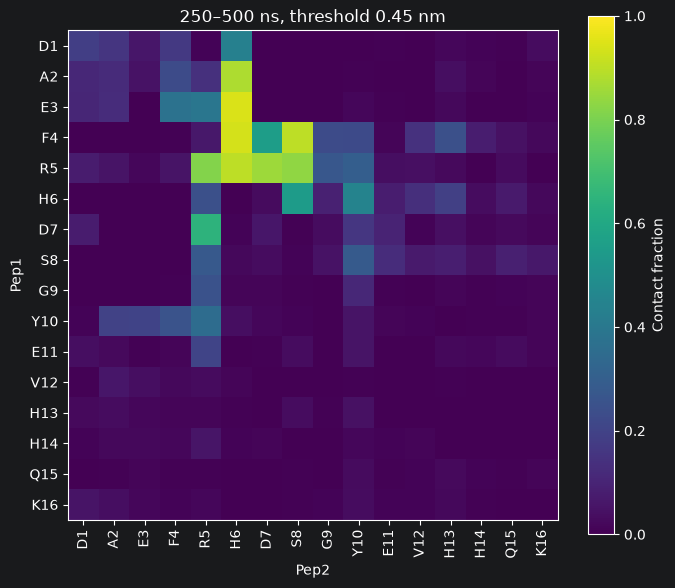

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(freq, vmin=0, vmax=1, cmap="viridis", origin="upper")
ax.set_xticks(range(n))
ax.set_xticklabels(labels, rotation=90)
ax.set_yticks(range(n))
ax.set_yticklabels(labels)
ax.set_xlabel("Pep2")
ax.set_ylabel("Pep1")
fig.colorbar(im, label="Contact fraction")
ax.set_title(f"{T_START:.0f}–{T_END:.0f} ns, threshold {CUTOFF/10:.2f} nm")
fig.tight_layout()
fig.savefig("contact_map.png", dpi=200)
plt.show()

Pep1   E3 – Pep2   H6: 0.94
Pep1   F4 – Pep2   H6: 0.94
Pep1   R5 – Pep2   H6: 0.90
Pep1   F4 – Pep2   S8: 0.90
Pep1   A2 – Pep2   H6: 0.88
Pep1   R5 – Pep2   D7: 0.85
Pep1   R5 – Pep2   S8: 0.83
Pep1   R5 – Pep2   R5: 0.81
Pep1   D7 – Pep2   R5: 0.65
Pep1   F4 – Pep2   D7: 0.56


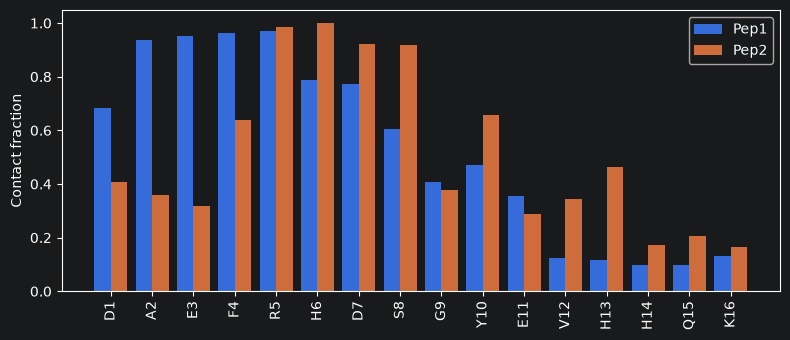

In [8]:
pairs = sorted(((freq[i, j], labels[i], labels[j]) for i in range(n) for j in range(n)), reverse=True)[:10]
for f, a, b in pairs:
    print(f"Pep1 {a:>4} – Pep2 {b:>4}: {f:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(n)
ax.bar(x - 0.2, any1 / nframes, width=0.4, label="Pep1")
ax.bar(x + 0.2, any2 / nframes, width=0.4, label="Pep2")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=90)
ax.set_ylabel("Contact fraction")
ax.legend()
fig.tight_layout()
fig.savefig("contact_profile.png", dpi=200)
plt.show()